
# Random Forest Regression

## 1. Import Libraries

In [ ]:
import pandas as pd
import numpy as np

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import matplotlib.pyplot as plt

## 2. Create Dataset

In [ ]:
import pandas as pd
import numpy as np

n_samples = 200

exp = np.random.randint(1, 25, n_samples)
projects = np.random.randint(1, 16, n_samples)

# Generate 'Salary' with a simpler linear relationship and added noise
# Salary = Base + (Exp_factor * EXP) + (Projects_factor * Projects) + Noise

# Define constants for salary calculation for clarity
base_salary_val = 50
exp_factor = 3.0
projects_factor = 7.0
noise_std_dev = 20

# Calculate salary by combining all components into one concise expression
salary = base_salary_val + \
         (exp * exp_factor) + \
         (projects * projects_factor) + \
         np.random.normal(0, noise_std_dev, n_samples)

# Ensure salaries are reasonably positive, setting a minimum
salary = np.maximum(salary, 30)

# Create the DataFrame
data = {
    'EXP': exp,
    'Projects': projects,
    'Salary': salary
}
df = pd.DataFrame(data)

print("Generated Extended Dataset:")
display(df.head())

Generated Extended Dataset:


,EXP,Projects,Salary
0,23,2,136.418758
1,6,14,164.213511
2,20,10,148.672005
3,11,8,122.230087
4,5,15,180.449528


In [ ]:
df.shape

(200, 3)

## 3. Separate Features and Target

In [ ]:
X = df[['EXP', 'Projects']]
y = df['Salary']

display(X)
display(y)

,EXP,Projects
0,23,2
1,6,14
2,20,10
3,11,8
4,5,15
...,...,...
195,2,7
196,3,12
197,15,5
198,7,6


,Salary
0,136.418758
1,164.213511
2,148.672005
3,122.230087
4,180.449528
...,...
195,74.577236
196,116.341792
197,158.797443
198,130.679933


## 4. Train-Test Split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


## 5. Bootstrap Sampling

Random Forest creates multiple random datasets using sampling with replacement.


In [ ]:

sample_1 = df.sample(n=len(df), replace=True, random_state=1)
sample_2 = df.sample(n=len(df), replace=True, random_state=2)

print("Bootstrap Sample 1")
display(sample_1)

print("Bootstrap Sample 2")
display(sample_2)


Bootstrap Sample 1


,EXP,Projects,Salary
37,8,15,188.113201
140,7,10,97.903231
72,13,5,134.352177
137,8,6,122.246604
133,15,1,128.699519
...,...,...,...
144,22,11,191.131650
156,6,6,101.104554
45,11,2,144.927177
195,2,7,74.577236


Bootstrap Sample 2


,EXP,Projects,Salary
168,24,5,155.112688
15,15,12,164.327256
72,13,5,134.352177
22,13,12,173.275818
43,23,2,159.456867
...,...,...,...
155,2,2,78.879715
195,2,7,74.577236
79,6,13,134.912248
130,16,10,189.162602


## 6. Create Random Forest Regressor

In [ ]:

model = RandomForestRegressor(
    n_estimators = 100,
    max_depth = 3,
    bootstrap=True,
    oob_score=True,
    random_state=42
)

model


RandomForestRegressor(max_depth=3, oob_score=True, random_state=42)

## 7. Train the Model

In [ ]:

model.fit(X_train, y_train)

RandomForestRegressor(max_depth=3, oob_score=True, random_state=42)

## 8. Predictions

In [ ]:
predictions = model.predict(X_test)

results = pd.DataFrame({
    'Actual Salary': y_test.values,
    'Predicted Salary': predictions
})

results


,Actual Salary,Predicted Salary
0,116.453133,100.242610
1,164.327256,183.624767
2,168.728379,156.882719
3,115.806311,113.535737
4,163.922174,145.274063
5,146.318975,171.510528
6,113.758873,114.148262
7,167.634854,156.882719
8,149.223426,134.903983
9,144.927177,108.082273


## 9. Predict New Data Point

In [ ]:
# Example new data point for prediction based on the extended dataset's features
# Keeping the original values, as they fall within the new plausible ranges for EXP (1-24) and Projects (1-15)
new_data_point = pd.DataFrame([{'EXP': 4, 'Projects': 3}])

# Convert new_data_point to NumPy array to avoid UserWarning about feature names
prediction = model.predict(new_data_point.values)

print("Predicted Salary for new data point (EXP=4, Projects=3):")
print(f"Salary: {prediction[0]:.2f}")

Predicted Salary for new data point (EXP=4, Projects=3):
Salary: 91.29


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(



## 10. Individual Tree Predictions

Each tree predicts separately.
Random Forest averages all predictions.


In [ ]:
all_predictions = []

# Define the new data point for individual tree predictions
new_data_point_for_trees = pd.DataFrame([{'EXP': 4, 'Projects': 3}])

print(f"Individual tree predictions for EXP=4, Projects=3:")
for i, tree_model in enumerate(model.estimators_[:5]): # Limiting to first 5 trees for brevity
    # Convert new_data_point_for_trees to NumPy array to avoid UserWarning about feature names
    pred = tree_model.predict(new_data_point_for_trees.values)[0]
    all_predictions.append(pred)
    print(f"Tree {i+1} Prediction: {pred:.2f}")

print("\nAverage Prediction from these trees: ", np.mean(all_predictions))

Individual tree predictions for EXP=4, Projects=3:
Tree 1 Prediction: 75.48
Tree 2 Prediction: 111.78
Tree 3 Prediction: 116.01
Tree 4 Prediction: 113.03
Tree 5 Prediction: 78.60

Average Prediction from these trees:  98.98084131872642



## 11. OOB Score (Out-of-Bag Score)

Rows not selected during bootstrap sampling become OOB samples.

Random Forest uses them for internal validation.


In [ ]:

print("OOB Score:", model.oob_score_)


OOB Score: 0.722400983721051


## 12. Evaluation Metrics

In [ ]:

mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = mse ** 0.5
r2 = r2_score(y_test, predictions)

print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)


MAE : 17.03363358922085
MSE : 475.95647770670246
RMSE: 21.816426785949673
R2 Score: 0.5715968707925396


## 13. Feature Importance

In [ ]:

importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.feature_importances_
})

importance_df


,Feature,Importance
0,EXP,0.247218
1,Projects,0.752782


## 14. Visualize Feature Importance

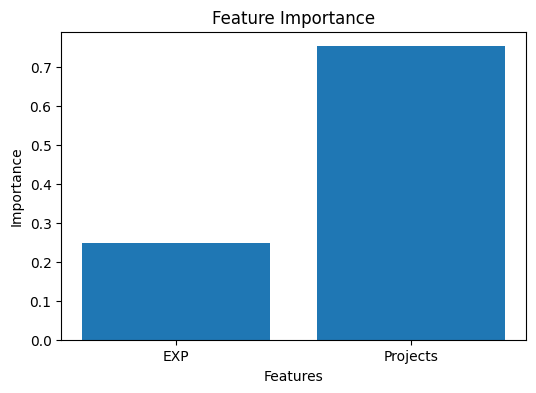

In [ ]:

plt.figure(figsize=(6,4))

plt.bar(
    importance_df['Feature'],
    importance_df['Importance']
)

plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("Feature Importance")

plt.show()



## 15. Hyperparameter Tuning Example


In [ ]:
# Change as per requirement
tuned_model = RandomForestRegressor(
    n_estimators=150,
    max_depth=3,
    min_samples_split=2,
    min_samples_leaf=1,
    bootstrap=True,
    oob_score=True,
    random_state=42
)

tuned_model.fit(X_train, y_train)

tuned_predictions = tuned_model.predict(X_test)

print("Tuned OOB Score:", tuned_model.oob_score_)
print("Tuned R2 Score :", r2_score(y_test, tuned_predictions))


Tuned OOB Score: 0.7245201369471281
Tuned R2 Score : 0.573731164682742


In [ ]:
n_trees = [50, 100, 150, 200, 250, 275, 300, 375]
depths = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

oob_scores = []
r2_scores = []

for i in n_trees:
  for j in depths:
    tuned_model = RandomForestRegressor(
        n_estimators=i,
        max_depth=j,
        min_samples_split=2,
        min_samples_leaf=1,
        bootstrap=True,
        oob_score=True,
        random_state=42
    )

    tuned_model.fit(X_train, y_train)

    tuned_predictions = tuned_model.predict(X_test)

    print("OOB Score:", tuned_model.oob_score_)
    print("R2 Score :", r2_score(y_test, tuned_predictions))
    oob_scores.append(tuned_model.oob_score_)
    r2_scores.append(r2_score(y_test, tuned_predictions))
    print("================================================")


print(f"Max OOB Score: {max(oob_scores)}")
print(f"Max R2 Score: {max(r2_scores)}")

OOB Score: 0.500757860180657
R2 Score : 0.22506864107199853
OOB Score: 0.674378591809177
R2 Score : 0.47906323860267974
OOB Score: 0.7221649106550266
R2 Score : 0.5840385158916954
OOB Score: 0.7324246731170694
R2 Score : 0.5978916279145688
OOB Score: 0.727829762520158
R2 Score : 0.5893083533431556
OOB Score: 0.7097979929303355
R2 Score : 0.5810015245096721
OOB Score: 0.6982446757358041
R2 Score : 0.5560464364244879
OOB Score: 0.6924511106185427
R2 Score : 0.5523922330486245
OOB Score: 0.6842761060794157
R2 Score : 0.5425523862424572
OOB Score: 0.6830375442664465
R2 Score : 0.5362462628219088
OOB Score: 0.5056062127111733
R2 Score : 0.22226076801909134
OOB Score: 0.6778079403658356
R2 Score : 0.4679807127048652
OOB Score: 0.722400983721051
R2 Score : 0.5715968707925396
OOB Score: 0.7355495339573183
R2 Score : 0.5823309515941945
OOB Score: 0.7319165104291063
R2 Score : 0.5771094904149954
OOB Score: 0.7140158324016207
R2 Score : 0.5793471295129162
OOB Score: 0.7036516523228609
R2 Score : 


# 16. Final Summary

Random Forest:

- Builds many decision trees
- Uses bootstrap sampling
- Uses random feature selection
- Averages predictions
- Reduces overfitting
- Produces stable predictions

Main concepts learned:

- Ensemble Learning
- Bootstrap Sampling
- OOB Score
- Feature Importance
- Hyperparameter Tuning
